# Proyecto KNN: clasificación de tumores de mama

## Objetivo
Desarrollar un modelo de inteligencia artificial que clasifique tumores de mama como **benignos** o **malignos** utilizando el algoritmo K-Nearest Neighbors (KNN).

## Datos utilizados
Trabajamos con una base de datos de **569 registros**, cinco características numéricas de los tumores y su diagnóstico.

El archivo CSV se carga directamente desde GitHub, por lo que se necesita conexión a internet al ejecutar el notebook.

## Pipeline del proyecto

El proyecto sigue el Pipeline de Machine Learning, y cada fase del notebook corresponde a una de sus etapas:

**Problema → Datos → Preprocesamiento → Modelo → Ajuste → Predicción → Evaluación**

| Fase | Pasos | ¿Qué hacemos? |
|---|---|---|
| 1. Problema | Paso 1 | Definir la tarea, conocer KNN y las matemáticas que necesita. |
| 2. Datos | Pasos 2 a 4 | Cargar el dataset, revisarlo y explorarlo con gráficas. |
| 3. Preprocesamiento | Paso 5 | Seleccionar variables, codificar el diagnóstico, separar entrenamiento y prueba, y escalar. |
| 4. Modelo | Paso 6 | Programar KNN manualmente y compararlo con scikit-learn. |
| 5. Ajuste | Pasos 7 y 8 | Probar valores de K con validación cruzada, elegir el mejor y entrenar el modelo final. |
| 6. Predicción | Paso 9 | Predecir sobre los datos de prueba. |
| 7. Evaluación | Pasos 10 a 12 | Medir los resultados, ver la frontera de decisión y concluir. |

# Fase 1. Problema

## Paso 1. Definir el problema

Queremos que la computadora clasifique cada tumor en una de dos categorías: **benigno** o **maligno**.

Es un problema de **clasificación binaria** porque solo existen dos respuestas posibles. Usaremos cinco características de los núcleos celulares para realizar la predicción.

Además del porcentaje general de aciertos, revisaremos cuántos tumores malignos consigue detectar el modelo.

## Fundamentos de KNN: ¿qué es KNN?

KNN significa *K-Nearest Neighbors* o **K vecinos más cercanos**.

**Explicación sencilla:**

Es un algoritmo que clasifica un dato nuevo comparándolo con otros datos que ya conoce. Busca los más parecidos y observa qué categoría se repite más.

**Ejemplo:**

Si elegimos K = 5 y, entre los cinco vecinos más cercanos, tres son malignos y dos benignos, el modelo clasifica el nuevo caso como maligno porque esa categoría obtuvo más votos.

**¿Cómo aprende?**

Durante el entrenamiento, KNN guarda los ejemplos. Cuando recibe un caso nuevo, calcula las distancias y busca sus vecinos más cercanos. Por eso también se conoce como *Lazy Learning* (aprendizaje perezoso): la mayor parte del trabajo ocurre al hacer la predicción.

### Ventajas y desventajas

| Ventajas | Desventajas |
|---|---|
| Es fácil de entender. | Puede ser lento con muchos datos. |
| Es sencillo de implementar. | Es sensible a la escala de las variables. |
| Puede clasificar diferentes categorías. | Puede verse afectado por variables poco útiles. |

## Abstracción matemática: ¿qué matemáticas utiliza KNN?

KNN utiliza las matemáticas para comparar tumores y encontrar cuáles se parecen más. Para entenderlo necesitamos tres ideas: **distancia euclidiana**, **distancia Manhattan** y **escalado de los datos**.

### A. Distancia euclidiana

**Explicación sencilla:** la distancia indica qué tan parecidos son dos tumores. Si sus características tienen valores casi iguales, la distancia es pequeña; si son muy diferentes, la distancia es grande. La distancia euclidiana es la medida "en línea recta", como la que se mediría con una regla.

$$d(x,z)=\sqrt{\sum_{j=1}^{m}(x_j-z_j)^2}$$

| Símbolo | Significado |
|---|---|
| $d(x,z)$ | Distancia entre el tumor $x$ y el tumor $z$ |
| $x$ | Tumor nuevo que queremos clasificar |
| $z$ | Tumor conocido (de los datos de entrenamiento) |
| $m$ | Número de características (en este proyecto, $m=5$) |
| $j$ | Número de la característica: 1 = radio, 2 = textura, y así sucesivamente |
| $x_j - z_j$ | Diferencia entre ambos tumores en la característica $j$ |
| $\sum_{j=1}^{m}$ | Sumar los resultados de la característica 1 hasta la $m$ |
| $\sqrt{\phantom{x}}$ | Raíz cuadrada |

**¿Cómo se usa en KNN?** El modelo calcula la distancia entre el tumor nuevo y **todos** los tumores conocidos. Los $K$ tumores con menor distancia son sus **vecinos más cercanos**.

**Ejemplo resuelto:** supongamos que dos tumores tienen solo dos características y sus diferencias son 3 y 4.

1. Elevamos cada diferencia al cuadrado: $3^2=9$ y $4^2=16$.
2. Sumamos: $9+16=25$.
3. Sacamos la raíz cuadrada: $\sqrt{25}=5$.

$$d=\sqrt{3^2+4^2}=\sqrt{9+16}=\sqrt{25}=5$$

La distancia euclidiana entre ambos tumores es **5**.

### B. Distancia Manhattan

**Explicación sencilla:** en lugar de medir la línea recta, suma cuánto se diferencian los tumores en cada característica, como al caminar por las calles de una ciudad: primero 3 cuadras en una dirección y luego 4 en la otra.

$$d(x,z)=\sum_{j=1}^{m}\lvert x_j-z_j\rvert$$

Los símbolos son los mismos de la fórmula anterior. La única novedad es $\lvert\ \rvert$, el **valor absoluto**, que quita el signo negativo de la diferencia (por ejemplo, $\lvert -3\rvert=3$).

**Ejemplo con las mismas diferencias (3 y 4):**

$$d=\lvert 3\rvert+\lvert 4\rvert=3+4=7$$

**¿Cuál es la diferencia?** Con las mismas diferencias, la euclidiana da **5** (línea recta) y la Manhattan da **7** (recorrido por cuadras). Son dos formas distintas de medir qué tan lejos están dos casos.

| Tipo de distancia | ¿Cómo funciona? | En scikit-learn |
|---|---|---|
| Euclidiana | Raíz de la suma de las diferencias al cuadrado. | `p=2` |
| Manhattan | Suma de las diferencias en valor absoluto. | `p=1` |

> **En este proyecto:** el modelo utiliza la **distancia euclidiana** (`p=2`, el valor por defecto de `KNeighborsClassifier`), igual que la función `knn_manual` del Paso 6. La distancia Manhattan se presenta solo como **alternativa teórica**: no se utiliza en el código.

### C. Escalado de los datos

**Explicación sencilla:** las características tienen magnitudes muy distintas. El área puede llegar a miles, mientras que la suavidad es menor que 1. Como la distancia suma las diferencias, las variables con números grandes dominarían el cálculo.

**Ejemplo ilustrativo** (valores inventados solo para entender la idea): el tumor A tiene área 500 y suavidad 0.10; el tumor B tiene área 900 y suavidad 0.14. Las diferencias son 400 y 0.04. Al elevarlas al cuadrado obtenemos 160,000 y 0.0016: la distancia es casi 400 y la suavidad prácticamente no influye.

Para evitarlo utilizamos la **estandarización** (`StandardScaler`):

$$z=\frac{x-\mu}{\sigma}$$

| Símbolo | Significado |
|---|---|
| $x$ | Valor original de la característica |
| $\mu$ | Media (promedio) de esa característica |
| $\sigma$ | Desviación estándar: qué tanto se separan, en promedio, los valores de la media |
| $z$ | Valor estandarizado |

**Ejemplo:** si un valor es 70, la media es 50 y la desviación estándar es 10:

$$z=\frac{70-50}{10}=2$$

El valor 70 está **2 desviaciones estándar por encima de la media**. Después de estandarizar, todas las características quedan en una escala comparable (media 0 y desviación estándar 1 en los datos de entrenamiento), y ninguna domina el cálculo de distancias.

> **Importante (fuga de información o *data leakage*):** en este proyecto `StandardScaler` se **ajusta únicamente con los datos de entrenamiento**: la media $\mu$ y la desviación $\sigma$ se calculan allí y luego se aplican igual a los datos de prueba. Además, el escalador va dentro de un `Pipeline`, de modo que en la validación cruzada se vuelve a ajustar en cada partición usando solo sus datos de entrenamiento. Si calculáramos $\mu$ y $\sigma$ con todos los datos, el modelo recibiría información de la parte de prueba y sus resultados parecerían mejores de lo que realmente son.

**En resumen:** KNN mide distancias, utiliza los votos de sus vecinos para clasificar y necesita que las variables estén en escalas comparables.

# Fase 2. Datos

## Paso 2. Cargar los datos

Primero importamos las herramientas que necesitaremos y después abrimos el archivo CSV, que contiene las características y el diagnóstico de cada tumor.

In [71]:
# --- Librerías para manejar datos y hacer cálculos ---
import numpy as np                      # Cálculos con arreglos numéricos (restas, sumas, raíces)
import pandas as pd                     # Tablas de datos (DataFrame)

# --- Librerías para hacer gráficas ---
import matplotlib.pyplot as plt         # Gráficas básicas (ejes, títulos, figuras)
import seaborn as sns                   # Gráficas estadísticas con mejor presentación
from matplotlib.colors import ListedColormap  # Permite elegir los colores de la frontera de decisión

# --- Herramientas de scikit-learn (aprendizaje automático) ---
# train_test_split: separa datos de entrenamiento y de prueba.
# StratifiedKFold: divide los datos en partes conservando la proporción de clases.
# cross_validate: realiza la validación cruzada (entrena y evalúa varias veces).
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler   # Estandariza: z = (x - media) / desviación estándar
from sklearn.pipeline import make_pipeline         # Encadena pasos (escalar y luego KNN) en un solo modelo
from sklearn.neighbors import KNeighborsClassifier # Algoritmo KNN
from sklearn.inspection import DecisionBoundaryDisplay  # Dibuja las zonas de decisión del modelo
# Métricas para evaluar el modelo y matriz de confusión
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Semilla fija: hace que las separaciones aleatorias sean siempre las mismas
# y que cualquiera obtenga los mismos resultados al ejecutar el notebook.
RANDOM_STATE = 42

# Las cinco características que usará el modelo (radio, textura, perímetro, área y suavidad).
FEATURES = [
    "mean_radius", "mean_texture", "mean_perimeter",
    "mean_area", "mean_smoothness"
]

# Estilo de las gráficas: fondo claro con cuadrícula.
sns.set_theme(style="whitegrid")

# Colores fijos para todas las gráficas: azul = benigno, rojo = maligno.
COLORES = {"benigno": "#377eb8", "maligno": "#e41a1c"}

In [72]:
# Dirección del archivo CSV con los datos de los tumores.
url = "https://raw.githubusercontent.com/Antonio-valenzuela/Machine-Learning-2026B/main/hands-on%206/hands-on%206/Breast_cancer_data.csv"

# Leer el CSV y guardarlo como tabla (DataFrame): cada fila es un tumor, cada columna una característica.
df = pd.read_csv(url)

# Mostrar los primeros cinco registros para confirmar que los datos se cargaron bien.
df.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


## Paso 3. Revisar los datos

Antes de entrenar, revisamos los valores de las cinco características. La tabla muestra el promedio, la desviación estándar, el valor mínimo y el máximo.

También veremos gráficas para comparar cómo se distribuyen las características en los tumores benignos y malignos.


In [73]:
# En el archivo original: 0 = maligno y 1 = benigno.
# Estas etiquetas se utilizan en las gráficas.
# map() cambia cada número por su texto, para que las leyendas sean fáciles de leer.
etiquetas_csv = df["diagnosis"].map({0: "maligno", 1: "benigno"})

# describe() calcula estadísticas básicas de cada columna (promedio, desviación estándar, mínimo, máximo...).
# .T intercambia filas y columnas para que cada característica quede en una fila.
# Mostrar estadísticas de las cinco características, sin incluir el diagnóstico.
resumen_datos = df[FEATURES].describe().T[["mean", "std", "min", "max"]]
resumen_datos.columns = ["Promedio", "Desviación estándar", "Mínimo", "Máximo"]

# Mostrar la tabla con tres decimales.
display(resumen_datos.round(3))

,Promedio,Desviación estándar,Mínimo,Máximo
mean_radius,14.127,3.524,6.981,28.110
mean_texture,19.290,4.301,9.710,39.280
mean_perimeter,91.969,24.299,43.790,188.500
mean_area,654.889,351.914,143.500,2501.000
mean_smoothness,0.096,0.014,0.053,0.163


### Gráficas de las características

Cada gráfica compara una característica entre tumores benignos y malignos. Cuando las distribuciones se separan, esa característica puede ayudar a distinguir las categorías.

En el archivo original, el diagnóstico está codificado como **0 = maligno** y **1 = benigno**. Más adelante cambiaremos esa codificación para trabajar con **0 = benigno** y **1 = maligno**.


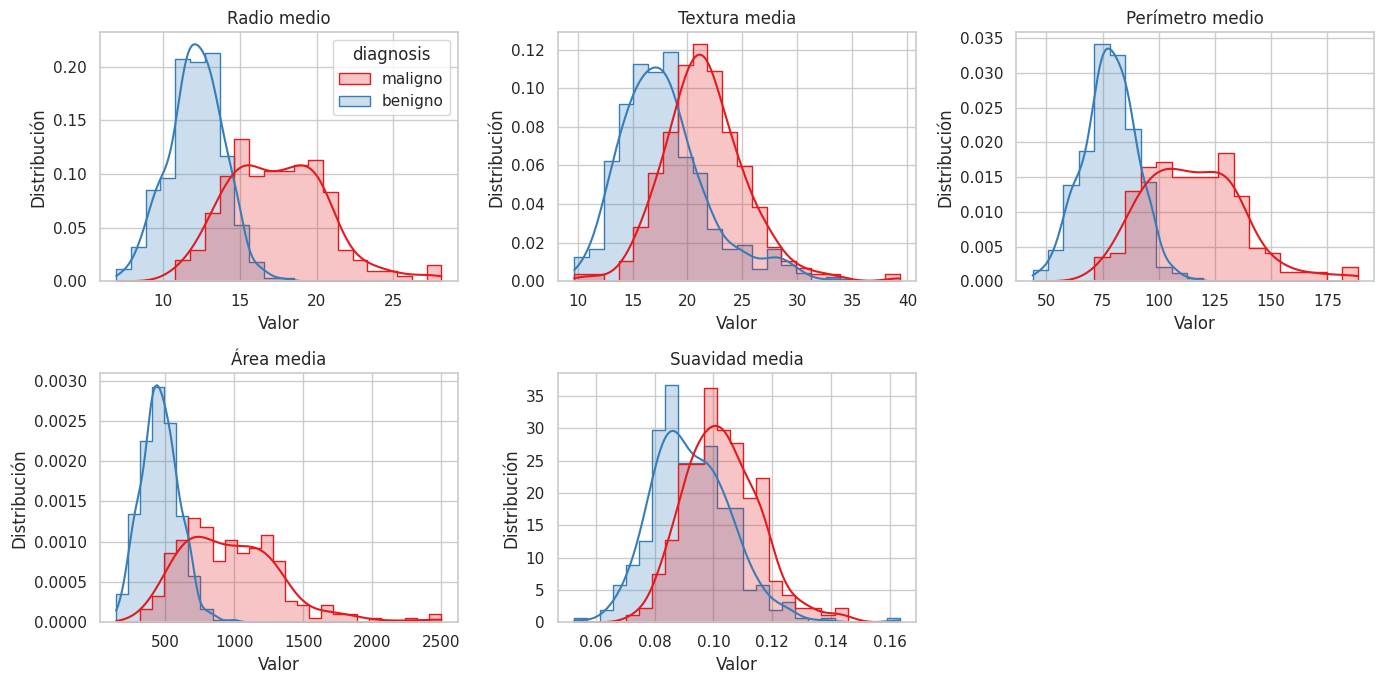

In [74]:
# Nombres en español para los títulos de cada gráfica.
# Mostrar la distribución de cada una de las cinco características.
titulos = {
    "mean_radius": "Radio medio",
    "mean_texture": "Textura media",
    "mean_perimeter": "Perímetro medio",
    "mean_area": "Área media",
    "mean_smoothness": "Suavidad media"
}

# Crear una cuadrícula de 2 filas x 3 columnas (seis espacios para gráficas).
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))

# Dibujar un histograma por característica, uno en cada espacio.
# ejes.ravel() convierte la cuadrícula de ejes en una lista simple.
for ax, col in zip(ejes.ravel(), FEATURES):
    # Eje horizontal: valor de la característica. Eje vertical: densidad (qué tan frecuentes son esos valores).
    # Color: diagnóstico (azul = benigno, rojo = maligno). La curva suave (kde) resume la forma de la distribución.
    # common_norm=False: cada diagnóstico se compara por separado, aunque haya distinta cantidad de casos.
    sns.histplot(
        data=df, x=col, hue=etiquetas_csv,
        palette=COLORES, kde=True, stat="density",
        common_norm=False, element="step",
        legend=(col == FEATURES[0]), ax=ax   # La leyenda solo aparece en la primera gráfica.
    )
    ax.set_title(titulos[col])
    ax.set_xlabel("Valor")
    ax.set_ylabel("Distribución")

# El sexto espacio queda vacío (solo hay cinco características), así que se oculta.
ejes.ravel()[-1].axis("off")

# Ajustar los espacios para que los títulos no se encimen y mostrar la figura.
plt.tight_layout()
plt.show()

### Relación entre las características

La matriz de correlación muestra qué tanto se relacionan dos características:

- Un valor cercano a **1** indica una relación positiva fuerte.
- Un valor cercano a **0** indica poca relación lineal.
- Un valor cercano a **-1** indica una relación negativa fuerte.

Nos ayuda a identificar características que pueden aportar información parecida.


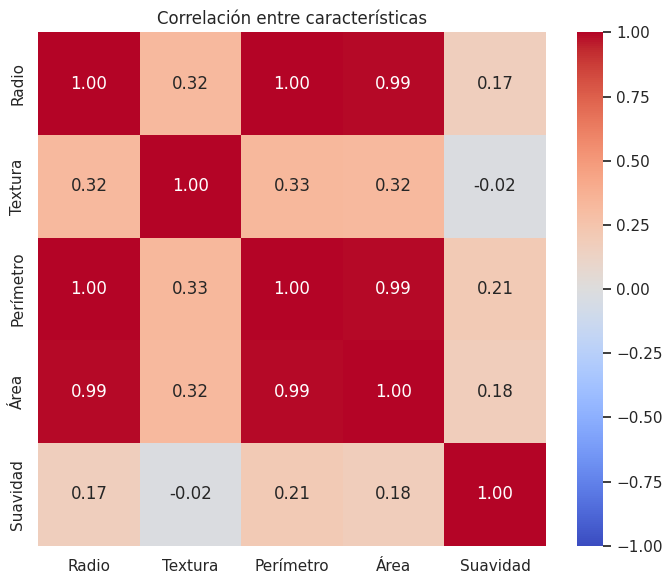

In [75]:
# corr() calcula la correlación entre cada par de características:
# un número entre -1 y 1 que indica qué tanto aumentan o disminuyen juntas.
# Calcular y mostrar la correlación entre las cinco características.
corr = df[FEATURES].corr()

# Nombres cortos en español para los ejes de la gráfica.
nombres = {
    "mean_radius": "Radio",
    "mean_texture": "Textura",
    "mean_perimeter": "Perímetro",
    "mean_area": "Área",
    "mean_smoothness": "Suavidad"
}
corr = corr.rename(index=nombres, columns=nombres)

# Mapa de calor: cada cuadro es la correlación entre la característica de su fila y la de su columna.
# annot=True escribe el número dentro del cuadro (con 2 decimales).
# Color: rojo = relación positiva, azul = negativa; la escala se fija entre -1 y 1.
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre características")
plt.tight_layout()
plt.show()

**¿Qué observamos?** El radio, el perímetro y el área tienen una relación muy fuerte entre sí. Esto significa que describen aspectos parecidos del tamaño del núcleo. Para KNN es importante reconocerlo porque varias características relacionadas pueden influir juntas en el cálculo de las distancias.


## Paso 4. Comparar dos características en una gráfica

Ahora representamos cada tumor como un punto. En el eje horizontal colocamos la textura y en el vertical el perímetro. Los colores indican el diagnóstico.

La gráfica permite observar si los tumores benignos y malignos forman grupos diferenciados.


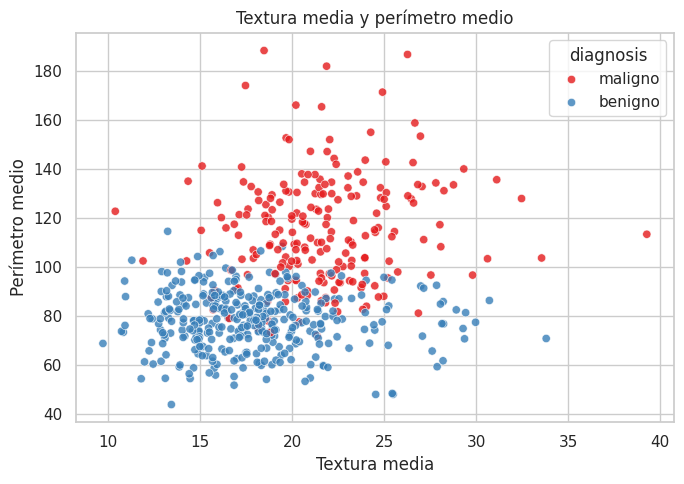

In [76]:
# Cada punto representa un tumor.
# Eje horizontal: textura media. Eje vertical: perímetro medio.
# Color: diagnóstico (azul = benigno, rojo = maligno). alpha=0.8 agrega transparencia para ver puntos encimados.
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="mean_texture",
    y="mean_perimeter",
    hue=etiquetas_csv,
    palette=COLORES,
    alpha=0.8
)
plt.title("Textura media y perímetro medio")
plt.xlabel("Textura media")
plt.ylabel("Perímetro medio")
plt.tight_layout()
plt.show()

# Fase 3. Preprocesamiento

## Paso 5. Preparar los datos

Antes de entrenar, hacemos cuatro cosas:

1. Seleccionamos las **cinco características** que utilizará el modelo.
2. Cambiamos las etiquetas para usar **0 = benigno** y **1 = maligno**.
3. Separamos los registros: **80 % para entrenamiento** y **20 % para prueba**.
4. **Escalamos** las características para que tengan una escala comparable.

La parte de prueba se reserva para evaluar el modelo al final. No la usamos para elegir el mejor K.

In [77]:
# X contiene las cinco características que utilizará el modelo para predecir.
X = df[FEATURES]

# Cambiar las etiquetas: 0 = benigno y 1 = maligno.
# Restar de 1 invierte los valores (0 pasa a 1 y 1 pasa a 0), así "maligno" queda como la clase 1,
# que es la que nos interesa detectar al calcular precisión y recall.
y = 1 - df["diagnosis"]

# Mostrar cuántos registros hay de cada categoría.
# value_counts() cuenta cuántas veces aparece cada valor.
conteo_clases = y.map({0: "Benigno", 1: "Maligno"}).value_counts()
conteo_clases.index.name = "Diagnóstico"
display(conteo_clases.to_frame("Cantidad"))

,Cantidad
Diagnóstico,
Benigno,357
Maligno,212


In [78]:
# Separar los datos para entrenar y después evaluar el modelo.
# train_test_split divide al azar los tumores en dos grupos:
#   test_size=0.20  -> 20 % para prueba y 80 % para entrenamiento.
#   stratify=y      -> ambos grupos conservan la misma proporción de benignos y malignos.
#   random_state    -> semilla para que la división sea siempre la misma.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Mostrar cuántos registros quedaron en cada grupo.
distribucion = pd.DataFrame({
    "Grupo": ["Entrenamiento", "Prueba"],
    "Registros": [len(y_train), len(y_test)]
})
display(distribucion)

,Grupo,Registros
0,Entrenamiento,455
1,Prueba,114


### Escalado de los datos

El escalador se ajusta solo con los datos de entrenamiento y después se aplica igual a los de prueba, para evitar fuga de información. La fórmula está en la sección de abstracción matemática.

In [79]:
# Ajustar el escalador solo con los datos de entrenamiento.
# fit() calcula y guarda la media (μ) y la desviación estándar (σ) de cada característica.
# Usar solo el entrenamiento evita que la parte de prueba influya en el escalado (fuga de información).
escalador = StandardScaler().fit(X_train)

# Transformar entrenamiento y prueba con la misma escala.
# transform() aplica z = (x - μ) / σ usando la media y la desviación aprendidas en fit().
Xtr = escalador.transform(X_train)
Xte = escalador.transform(X_test)

# Convertir los diagnósticos a un arreglo de NumPy para poder seleccionarlos por posición
# dentro de la función knn_manual.
ytr = y_train.to_numpy()

# Fase 4. Modelo

## Paso 6. Construir KNN manualmente y con scikit-learn

Antes de usar la herramienta de scikit-learn, programamos una versión sencilla de KNN. Así podemos ver sus pasos:

1. Calcular las distancias entre el tumor nuevo y los tumores conocidos.
2. Elegir los K más cercanos.
3. Contar sus diagnósticos y elegir el que tenga más votos.

Después comparamos esta versión con la herramienta de scikit-learn. Ambas usan los datos escalados de la fase anterior.

In [80]:
# Función que clasifica UN tumor nuevo con el algoritmo KNN.
#   x_nuevo: valores (ya escalados) del tumor que queremos clasificar.
#   X_ref:   tumores conocidos (una fila por tumor, una columna por característica).
#   y_ref:   diagnóstico de cada tumor conocido (0 = benigno, 1 = maligno).
#   k:       cantidad de vecinos que votan.
def knn_manual(x_nuevo, X_ref, y_ref, k):
    # Paso 1: calcular la distancia euclidiana entre el tumor nuevo y todos los tumores conocidos.
    #   (X_ref - x_nuevo)   -> diferencia en cada característica, fila por fila
    #   ** 2                -> elevar cada diferencia al cuadrado
    #   .sum(axis=1)        -> sumar las diferencias de cada tumor (axis=1 suma a lo largo de las columnas)
    #   np.sqrt(...)        -> raíz cuadrada: así se obtiene d(x, z) = √Σ(xj - zj)²
    distancias = np.sqrt(((X_ref - x_nuevo) ** 2).sum(axis=1))

    # Paso 2: ordenar y elegir a los vecinos.
    # argsort() devuelve las posiciones de los tumores ordenadas de la menor a la mayor distancia;
    # [:k] se queda con las posiciones de los K más cercanos.
    vecinos = np.argsort(distancias)[:k]

    # Paso 3: contar los votos.
    # y_ref[vecinos] son los diagnósticos de los vecinos. Como maligno = 1 y benigno = 0,
    # sumarlos equivale a contar cuántos vecinos son malignos.
    votos_malignos = y_ref[vecinos].sum()

    # Paso 4: decidir por mayoría.
    # Si más de la mitad de los K vecinos son malignos (votos > k/2), devolver 1; si no, devolver 0.
    # int() convierte el resultado True/False en 1/0.
    return int(votos_malignos > k / 2)

In [81]:
# Predecir con nuestra función y con scikit-learn usando K = 5.
# Versión manual: se aplica knn_manual a cada tumor de prueba (cada fila de Xte).
pred_manual = np.array([knn_manual(x, Xtr, ytr, k=5) for x in Xte])

# Versión de scikit-learn:
#   KNeighborsClassifier(n_neighbors=5) crea el modelo con 5 vecinos (todavía sin datos).
#   fit() "entrena": en KNN solo guarda los tumores de entrenamiento.
#   predict() busca los 5 vecinos de cada tumor de prueba y devuelve la categoría ganadora.
pred_sklearn = KNeighborsClassifier(n_neighbors=5).fit(Xtr, y_train).predict(Xte)

# Comprobar si ambas versiones dieron las mismas respuestas.
# (pred_manual == pred_sklearn) da True/False por tumor; mean() calcula la proporción de True.
coincidencia = (pred_manual == pred_sklearn).mean()
print(f"Coincidencia entre las dos versiones: {coincidencia:.0%}")

Coincidencia entre las dos versiones: 100%


# Fase 5. Ajuste

## Paso 7. Elegir la cantidad de vecinos (K)

No sabemos de antemano cuál es el mejor número de vecinos. Por eso probamos distintos valores impares, desde 1 hasta 31 (con dos categorías, un K impar evita empates en la votación).

Utilizamos **validación cruzada de 5 partes**: el conjunto de entrenamiento se divide en cinco grupos y el modelo se prueba varias veces, cambiando el grupo que se deja para validar.

Comparamos dos medidas:
- **Accuracy:** proporción total de predicciones correctas.
- **Recall del maligno:** proporción de tumores malignos reales que el modelo consigue detectar.

Elegimos K según el mejor accuracy promedio. La parte de prueba se mantiene separada y no participa en esta elección.

In [82]:
# Probar cantidades impares de vecinos: 1, 3, 5, ..., 31.
# (Impares para evitar empates en la votación entre dos categorías.)
valores_k = list(range(1, 32, 2))

# Dividir el entrenamiento en cinco partes, conservando la proporción de clases.
# shuffle=True mezcla los datos antes de dividirlos; random_state hace que la mezcla sea repetible.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Función que evalúa cada valor de K con validación cruzada, usando solo las columnas indicadas.
def evaluar_k(columnas):
    filas = []

    for k in valores_k:
        # Primero escala los datos y después aplica KNN.
        # Dentro de la validación cruzada, el escalador se ajusta en cada partición solo con
        # sus datos de entrenamiento, así la parte de validación no influye en μ ni en σ.
        modelo = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=k)
        )

        # cross_validate entrena y evalúa el modelo cinco veces; en cada vuelta una parte distinta
        # se usa para validar y las otras cuatro para entrenar.
        #   accuracy: proporción de predicciones correctas.
        #   recall:   proporción de tumores malignos reales que se detectaron.
        # Devuelve cinco valores de cada métrica (uno por partición).
        resultados_cv = cross_validate(
            modelo,
            X_train[columnas],
            y_train,
            cv=cv,
            scoring={"accuracy": "accuracy", "recall": "recall"}
        )

        # Guardar el promedio (mean) y la variación entre particiones (std) para este valor de K.
        filas.append({
            "k": k,
            "accuracy_media": resultados_cv["test_accuracy"].mean(),
            "accuracy_std": resultados_cv["test_accuracy"].std(),
            "recall_media": resultados_cv["test_recall"].mean(),
            "recall_std": resultados_cv["test_recall"].std()
        })

    # Devolver una tabla con una fila por cada valor de K.
    return pd.DataFrame(filas)

In [83]:
# Evaluar los distintos valores de K usando las cinco características.
resultados = evaluar_k(FEATURES)

# Elegir el K con el accuracy promedio más alto.
# idxmax() devuelve la fila con el mayor accuracy_media; loc[...] selecciona esa fila.
mejor = resultados.loc[resultados["accuracy_media"].idxmax()]
mejor_k = int(mejor["k"])

# Mostrar solamente el resumen del mejor resultado.
resumen_k = pd.DataFrame({
    "Mejor K": [mejor_k],
    "Accuracy promedio": [mejor["accuracy_media"]],
    "Variación del accuracy": [mejor["accuracy_std"]],
    "Recall de malignos": [mejor["recall_media"]]
})
display(resumen_k.round(3))

,Mejor K,Accuracy promedio,Variación del accuracy,Recall de malignos
0,15,0.941,0.018,0.865


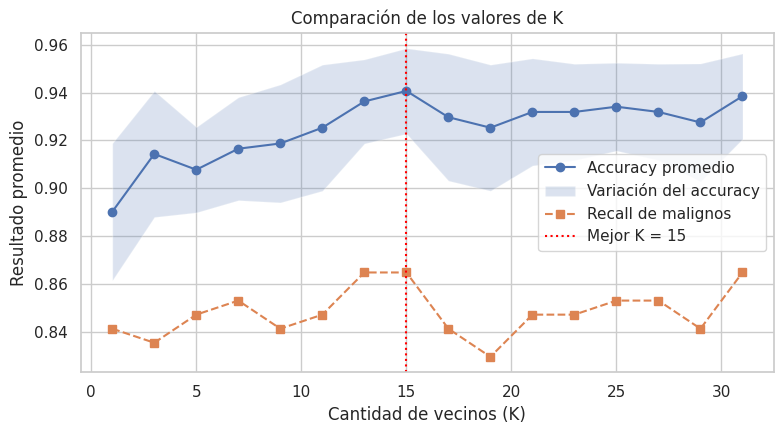

In [84]:
# Comparar el accuracy y el recall obtenidos con cada valor de K.
# Eje horizontal: cantidad de vecinos (K). Eje vertical: resultado promedio (entre 0 y 1).
plt.figure(figsize=(8, 4.5))

# Línea con círculos: accuracy promedio de cada K.
plt.plot(resultados["k"], resultados["accuracy_media"], marker="o", label="Accuracy promedio")

# Banda sombreada: accuracy promedio ± su desviación estándar (qué tanto varió entre particiones).
plt.fill_between(
    resultados["k"],
    resultados["accuracy_media"] - resultados["accuracy_std"],
    resultados["accuracy_media"] + resultados["accuracy_std"],
    alpha=0.2,
    label="Variación del accuracy"
)

# Línea discontinua con cuadrados: recall de los tumores malignos.
plt.plot(resultados["k"], resultados["recall_media"], marker="s", linestyle="--", label="Recall de malignos")

# Línea vertical roja: marca el mejor K elegido.
plt.axvline(mejor_k, color="red", linestyle=":", label=f"Mejor K = {mejor_k}")
plt.xlabel("Cantidad de vecinos (K)")
plt.ylabel("Resultado promedio")
plt.title("Comparación de los valores de K")
plt.legend()
plt.tight_layout()
plt.show()

## Paso 8. Entrenar el modelo

Ya elegimos el mejor valor de K. Ahora entrenamos el modelo con todos los datos reservados para entrenamiento.

El proceso también aplica el escalado antes de utilizar KNN.


In [85]:
# Crear el modelo con el mejor K y entrenarlo.
# Un Pipeline une los pasos en orden: primero StandardScaler y después KNN.
modelo_final = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=mejor_k)
)

# fit() ejecuta el pipeline con los datos de entrenamiento: el escalador calcula μ y σ y escala los datos
# (fit_transform), y luego KNN guarda esos ejemplos escalados.
# El ";" al final evita que Jupyter imprima la descripción del modelo.
modelo_final.fit(X_train, y_train);

# Fase 6. Predicción

## Paso 9. Realizar predicciones

Ahora usamos el modelo con los datos de prueba, que no utilizamos para entrenarlo.

- `predict()` devuelve el diagnóstico que predice el modelo.
- `predict_proba()` muestra la proporción de vecinos que votaron por cada categoría. Aquí mostramos la proporción de votos a favor de maligno.

In [86]:
# Obtener el diagnóstico predicho y la proporción de votos malignos.
# predict() escala X_test con la μ y σ del entrenamiento (transform) y devuelve 0 (benigno) o 1 (maligno).
y_pred = modelo_final.predict(X_test)

# predict_proba() devuelve dos columnas: [proporción de votos benigno, proporción de votos maligno].
# [:, 1] se queda con la segunda columna (maligno): votos malignos / K.
y_proba = modelo_final.predict_proba(X_test)[:, 1]

# Comparar el diagnóstico real con el predicho en los primeros ocho casos.
# [:8] toma los ocho primeros; map() convierte 0/1 en texto; multiplicar por 100 expresa la proporción en %.
resultados_prediccion = pd.DataFrame({
    "Diagnóstico real": pd.Series(y_test.values[:8]).map({0: "Benigno", 1: "Maligno"}),
    "Predicción del modelo": pd.Series(y_pred[:8]).map({0: "Benigno", 1: "Maligno"}),
    "Vecinos que votaron maligno (%)": (y_proba[:8] * 100).round(0)
})
display(resultados_prediccion)

,Diagnóstico real,Predicción del modelo,Vecinos que votaron maligno (%)
0,Benigno,Benigno,0.0
1,Maligno,Maligno,100.0
2,Benigno,Benigno,40.0
3,Maligno,Benigno,40.0
4,Benigno,Benigno,33.0
5,Benigno,Benigno,0.0
6,Maligno,Maligno,60.0
7,Benigno,Benigno,0.0


# Fase 7. Evaluación

## Paso 10. Evaluar el modelo

Comparamos las predicciones con los diagnósticos reales de los datos de prueba.

| Medida | ¿Qué nos dice? |
|---|---|
| **Accuracy** | Qué porcentaje de todos los casos clasificó correctamente. |
| **Precisión del maligno** | De los casos que marcó como malignos, cuántos realmente lo eran. |
| **Recall del maligno** | De todos los tumores malignos reales, cuántos logró detectar. |
| **F1 del maligno** | Resume el equilibrio entre precisión y recall. |

También usamos una matriz de confusión para ver los aciertos y errores.

In [87]:
# Calcular las métricas principales del modelo comparando lo real (y_test) con lo predicho (y_pred).
# pos_label=1 indica que la clase de interés es "maligno".
# Accuracy: porcentaje de todos los casos clasificados correctamente.
acc = accuracy_score(y_test, y_pred)

# Precisión: de los tumores que el modelo marcó como malignos, cuántos realmente lo eran.
prec = precision_score(y_test, y_pred, pos_label=1)

# Recall: de todos los tumores malignos reales, cuántos logró detectar.
rec = recall_score(y_test, y_pred, pos_label=1)

# F1: combina precisión y recall en un solo número (es alto solo si ambos son altos).
f1 = f1_score(y_test, y_pred, pos_label=1)

# Mostrar las métricas como porcentaje (proporción x 100).
metricas = pd.DataFrame({
    "Medida": ["Accuracy", "Precisión de malignos", "Recall de malignos", "F1 de malignos"],
    "Resultado (%)": [acc * 100, prec * 100, rec * 100, f1 * 100]
})
display(metricas.round(1))

,Medida,Resultado (%)
0,Accuracy,92.1
1,Precisión de malignos,92.3
2,Recall de malignos,85.7
3,F1 de malignos,88.9


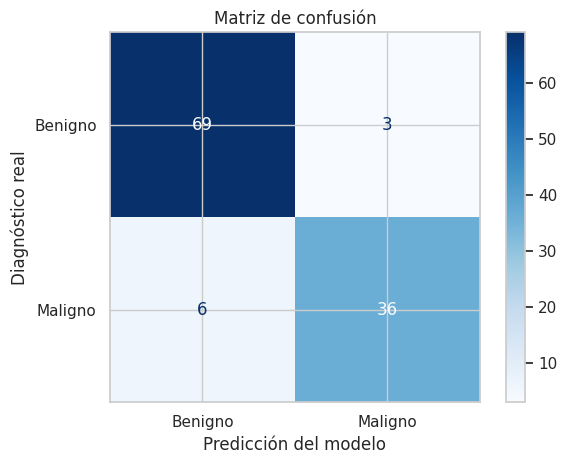

In [88]:
# Mostrar los aciertos y errores del modelo.
# confusion_matrix cuenta los casos reales (filas) contra los predichos (columnas).
# labels=[0, 1] fija el orden: benigno primero y maligno después.
# Resultado: [[verdaderos negativos, falsos positivos], [falsos negativos, verdaderos positivos]].
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Preparar el dibujo de la matriz con nombres legibles.
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benigno", "Maligno"]
)

# Cada cuadro muestra cuántos tumores cayeron en esa combinación; mientras más oscuro, más casos.
# Eje horizontal: predicción del modelo. Eje vertical: diagnóstico real.
display_cm.plot(cmap="Blues")
display_cm.ax_.set_xlabel("Predicción del modelo")
display_cm.ax_.set_ylabel("Diagnóstico real")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

**Cómo interpretar la matriz:**

- **Verdadero positivo:** el tumor era maligno y el modelo lo identificó como maligno. 36
- **Verdadero negativo:** el tumor era benigno y el modelo lo identificó como benigno. 69
- **Falso positivo:** era benigno, pero el modelo indicó maligno. 3
- **Falso negativo:** era maligno, pero el modelo indicó benigno. 6

En este ejercicio debemos prestar especial atención a los **falsos negativos**, porque representan tumores malignos que el modelo no detectó. Este notebook es académico y no debe utilizarse para realizar diagnósticos médicos.


## Paso 11. Ver la frontera de decisión

La frontera de decisión es un gráfico que muestra las zonas donde el modelo clasificaría un tumor como benigno o maligno.

Para poder dibujarla utilizamos solamente dos características: textura media y perímetro medio. Cada punto representa un tumor y el color del fondo muestra la categoría que elegiría KNN en esa zona.

Como este modelo utiliza dos características en lugar de cinco, buscamos para él su propio valor de K.


In [89]:
# Seleccionar las dos características que aparecerán en la gráfica.
dos = ["mean_texture", "mean_perimeter"]

# Buscar el mejor K utilizando solamente esas dos características
# (se reutiliza la función evaluar_k del Paso 7).
resultados_2d = evaluar_k(dos)
mejor_2d = resultados_2d.loc[resultados_2d["accuracy_media"].idxmax()]
k_2d = int(mejor_2d["k"])

resumen_2d = pd.DataFrame({
    "Mejor K (2 características)": [k_2d],
    "Accuracy promedio": [mejor_2d["accuracy_media"]],
    "Recall de malignos": [mejor_2d["recall_media"]]
})
display(resumen_2d.round(3))

,Mejor K (2 características),Accuracy promedio,Recall de malignos
0,13,0.905,0.818


In [90]:
# Entrenar el modelo que utiliza solo dos características.
# Igual que antes: el pipeline escala los datos y después aplica KNN con el K encontrado para dos variables.
modelo_2d = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=k_2d)
)
modelo_2d.fit(X_train[dos], y_train);

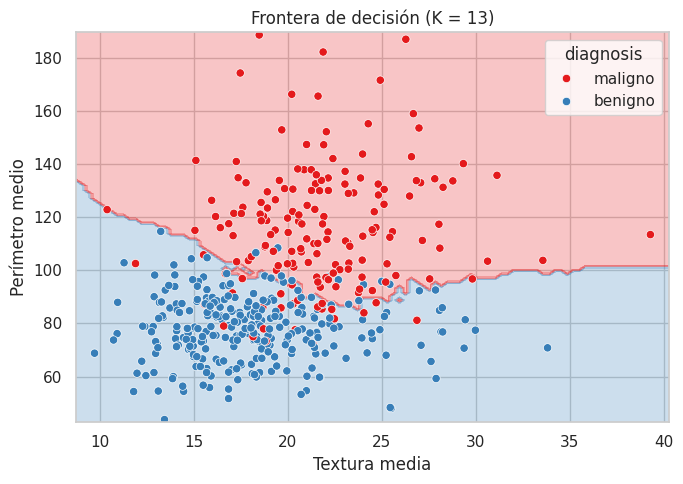

In [91]:
# Dibujar las zonas de clasificación y los tumores de entrenamiento.
fig, ax = plt.subplots(figsize=(7, 5))

# Colorear el fondo según lo que predice el modelo: DecisionBoundaryDisplay crea una cuadrícula de puntos
# sobre el rango de las dos características y le pide una predicción al modelo para cada punto.
# Fondo azul = zona donde predice benigno; fondo rojo = zona donde predice maligno.
# alpha=0.25 hace el color más suave para que se vean los puntos.
DecisionBoundaryDisplay.from_estimator(
    modelo_2d,
    X_train[dos],
    response_method="predict",
    alpha=0.25,
    cmap=ListedColormap([COLORES["benigno"], COLORES["maligno"]]),
    ax=ax
)

# Dibujar encima cada tumor de entrenamiento como un punto, coloreado por su diagnóstico real.
# Eje horizontal: textura media. Eje vertical: perímetro medio.
sns.scatterplot(
    x=X_train[dos[0]],
    y=X_train[dos[1]],
    hue=y_train.map({0: "benigno", 1: "maligno"}),
    palette=COLORES,
    ax=ax
)

ax.set_title(f"Frontera de decisión (K = {k_2d})")
ax.set_xlabel("Textura media")
ax.set_ylabel("Perímetro medio")
plt.tight_layout()
plt.show()

In [92]:
# Comparar el resultado del modelo de dos características con el de cinco.
# Se predice con los datos de prueba, usando solo las dos columnas del modelo reducido,
# y accuracy_score mide qué proporción de casos acertó.
acc_2d = accuracy_score(y_test, modelo_2d.predict(X_test[dos]))

comparacion_modelos = pd.DataFrame({
    "Modelo": ["Cinco características", "Dos características"],
    "K utilizado": [mejor_k, k_2d],
    "Accuracy en prueba (%)": [acc * 100, acc_2d * 100]
})
display(comparacion_modelos.round(1))

,Modelo,K utilizado,Accuracy en prueba (%)
0,Cinco características,15,92.1
1,Dos características,13,92.1


## Paso 12. Conclusiones

En este proyecto utilizamos KNN para clasificar tumores de mama como benignos o malignos a partir de cinco características.

### Resultados de esta ejecución

- El mejor valor encontrado fue **K = 15**.
- En los datos de prueba, el modelo obtuvo **92.1 % de accuracy**.
- El recall de malignos fue **85.7 %**: detectó 36 de los 42 tumores malignos y no detectó 6.
- La precisión de malignos fue **92.3 %**.
- Al escalar los datos, el accuracy pasó de **87.7 % a 92.1 %** y el recall de malignos de **71.4 % a 85.7 %**.
- El modelo de dos características obtuvo también **92.1 % de accuracy** en esta partición de prueba, aunque utiliza menos información.

### ¿Qué aprendimos?

KNN compara un caso nuevo con los ejemplos que ya conoce. Para hacerlo necesita calcular distancias, elegir la cantidad adecuada de vecinos y preparar las características para que tengan escalas comparables.

También aprendimos que no basta con revisar el porcentaje total de aciertos. En este problema es importante observar cuántos tumores malignos no fueron detectados.

### Limitaciones

Este ejercicio utiliza una base de datos específica y solo cinco características. Los resultados dependen de los datos y de cómo se separen para entrenamiento y prueba. **El modelo es una práctica académica y no sustituye la valoración de profesionales ni sirve como herramienta de diagnóstico médico.**

### Referencias

- Kaggle, *Breast Cancer Prediction Dataset*: https://www.kaggle.com/datasets/merishnasuwal/breast-cancer-prediction-dataset
- Scikit-learn, documentación de `KNeighborsClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
- Archivo CSV utilizado: https://raw.githubusercontent.com/Antonio-valenzuela/Machine-Learning-2026B/main/hands-on%206/hands-on%206/Breast_cancer_data.csv
